In [2]:
import os
GPU_ID = "3"  # physical DGX GPU; visible to TensorFlow as /GPU:0
os.environ["CUDA_VISIBLE_DEVICES"] = GPU_ID
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"

import glob
import random
from pathlib import Path
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, Model

# -------------------------
# Dataset and model settings
# -------------------------
ROOT_DIR = Path("/raid/home/dgx1725/Warwick_QU_Dataset_Binary_FIXED")
IMG_HEIGHT = 256
IMG_WIDTH = 384
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)  # (height, width)
BATCH_SIZE = 1
EPOCHS = 50
SEED = 42
BOUNDARY_TOLERANCE_PX = 2
BOUNDARY_TOLERANCE = BOUNDARY_TOLERANCE_PX
PRED_THRESHOLD = 0.5
BASE_FILTERS = [32, 64, 128, 256, 512]  # full-width U-Net++ encoder/decoder schedule
OUTPUT_DIR = "/raid/home/dgx1725/unetpp_mod3_learnablekernel_warwick_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "predicted_masks"), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "prediction_visualizations"), exist_ok=True)

# Compatibility aliases: train directories only. Split-aware code below uses SPLIT_DIRS.
IMAGE_DIR = str(ROOT_DIR / "train" / "img")
MASK_DIR = str(ROOT_DIR / "train" / "mask")
SPLIT_DIRS = {
    split: {
        "img": ROOT_DIR / split / "img",
        "mask": ROOT_DIR / split / "mask",
    }
    for split in ("train", "val", "test")
}

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE

# GPU check + memory growth. Full paper-width filters are intentionally retained.
physical_gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow version:", tf.__version__)
print("Requested physical GPU ID:", GPU_ID)
print("TensorFlow-visible GPUs:", physical_gpus)
if not physical_gpus:
    raise RuntimeError(
        "TensorFlow sees no GPU. Restart the kernel and launch Jupyter from the DGX "
        "terminal with the appropriate NVIDIA LD_LIBRARY_PATH and CUDA_VISIBLE_DEVICES."
    )
for gpu in physical_gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as exc:
        print("GPU memory-growth setting:", exc)
with tf.device("/GPU:0"):
    _gpu_test = tf.matmul(tf.random.normal((128, 128)), tf.random.normal((128, 128)))
print("GPU matrix test device:", _gpu_test.device)
del _gpu_test

if not ROOT_DIR.is_dir():
    raise FileNotFoundError(f"Dataset root not found: {ROOT_DIR}")
for split, paths in SPLIT_DIRS.items():
    for kind, folder in paths.items():
        if not folder.is_dir():
            raise FileNotFoundError(f"Missing {split}/{kind} directory: {folder}")

print("Dataset root:", ROOT_DIR)
print("Output directory:", OUTPUT_DIR)
for split, paths in SPLIT_DIRS.items():
    print(f"{split:5s} | images={sum(p.is_file() for p in paths['img'].iterdir())} | masks={sum(p.is_file() for p in paths['mask'].iterdir())}")
print("Input tensor shape:", (IMG_HEIGHT, IMG_WIDTH, 3))
print("U-Net++ filter schedule:", BASE_FILTERS)


TensorFlow version: 2.15.1
Requested physical GPU ID: 3
TensorFlow-visible GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU matrix test device: /job:localhost/replica:0/task:0/device:GPU:0
Dataset root: /raid/home/dgx1725/Warwick_QU_Dataset_Binary_FIXED
Output directory: /raid/home/dgx1725/unetpp_mod3_learnablekernel_warwick_outputs
train | images=133 | masks=133
val   | images=16 | masks=16
test  | images=16 | masks=16
Input tensor shape: (256, 384, 3)
U-Net++ filter schedule: [32, 64, 128, 256, 512]


In [3]:
# ============================================================
# SPLIT-AWARE IMAGE/MASK PAIRING + INPUT PIPELINE
# Each split has img/ and mask/; e.g. testA_47.png pairs with testA_47_anno.png.
# The existing train/val/test split is preserved exactly; no random split is made.
# ============================================================
VALID_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".bm", ".tif", ".tiff"}


def canonical_mask_stem(path):
    """Remove the Warwick QU annotation suffix from mask names."""
    stem = Path(path).stem
    if stem.lower().endswith("_anno"):
        stem = stem[:-5]
    return stem


def get_pairs(image_dir, mask_dir, split_name="dataset"):
    image_dir, mask_dir = Path(image_dir), Path(mask_dir)
    image_paths = sorted(
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in VALID_EXTS
    )
    mask_map = {}
    for path in sorted(mask_dir.iterdir()):
        if not path.is_file() or path.suffix.lower() not in VALID_EXTS:
            continue
        stem = canonical_mask_stem(path)
        if stem in mask_map:
            raise ValueError(
                f"Duplicate masks map to the same image stem '{stem}' in {mask_dir}: "
                f"{mask_map[stem].name}, {path.name}"
            )
        mask_map[stem] = path

    pairs = []
    missing_masks = []
    used_mask_stems = set()
    for img_path in image_paths:
        stem = img_path.stem
        mask_path = mask_map.get(stem)
        if mask_path is None:
            missing_masks.append(img_path.name)
            continue
        pairs.append((str(img_path), str(mask_path)))
        used_mask_stems.add(stem)

    extra_masks = sorted(set(mask_map) - used_mask_stems)
    print(
        f"{split_name}: images={len(image_paths)}, masks={len(mask_map)}, "
        f"paired={len(pairs)}, missing_masks={len(missing_masks)}, extra_masks={len(extra_masks)}"
    )
    if missing_masks:
        raise ValueError(
            f"{split_name}: no matching mask for {len(missing_masks)} image(s). "
            f"Examples: {missing_masks[:10]}. Expected image.png / image_anno.png pairing."
        )
    if extra_masks:
        print(f"Warning: {split_name} has masks without an image, e.g. {extra_masks[:10]}")
    if not pairs:
        raise ValueError(f"No image-mask pairs found for split '{split_name}'.")
    return pairs


train_pairs = get_pairs(SPLIT_DIRS["train"]["img"], SPLIT_DIRS["train"]["mask"], "train")
val_pairs = get_pairs(SPLIT_DIRS["val"]["img"], SPLIT_DIRS["val"]["mask"], "val")
test_pairs = get_pairs(SPLIT_DIRS["test"]["img"], SPLIT_DIRS["test"]["mask"], "test")
# Convenience concatenation for auditing only; never use it to split the dataset.
pairs = train_pairs + val_pairs + test_pairs


def _path_value(value):
    """Decode paths from tf.numpy_function or accept normal Python strings."""
    if isinstance(value, np.ndarray):
        value = value.item()
    if isinstance(value, (bytes, np.bytes_)):
        value = value.decode("utf-8")
    return os.fspath(value)


def load_image_mask(img_path, mask_path):
    img_path = _path_value(img_path)
    mask_path = _path_value(mask_path)

    img = cv2.imread(img_path, cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError(f"Could not read image: {img_path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    # OpenCV takes (width, height); IMG_SIZE is stored as (height, width).
    img = cv2.resize(img, (IMG_WIDTH, IMG_HEIGHT), interpolation=cv2.INTER_AREA)
    img = img.astype(np.float32) / 255.0

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"Could not read mask: {mask_path}")
    mask = cv2.resize(mask, (IMG_WIDTH, IMG_HEIGHT), interpolation=cv2.INTER_NEAREST)
    # The prepared dataset stores foreground as 255 and background as 0.
    # Keep the mask binary (0/1) for BCE + Dice training.
    mask = (mask > 127).astype(np.float32)
    mask = np.expand_dims(mask, axis=-1)
    return img, mask


def tf_load_image_mask(img_path, mask_path):
    img, mask = tf.numpy_function(
        func=load_image_mask,
        inp=[img_path, mask_path],
        Tout=[tf.float32, tf.float32],
    )
    img.set_shape([IMG_HEIGHT, IMG_WIDTH, 3])
    mask.set_shape([IMG_HEIGHT, IMG_WIDTH, 1])
    return img, mask


def duplicate_mask(image, mask):
    """Supply a full-resolution mask to each of the 4 deep-supervision outputs."""
    return image, (mask, mask, mask, mask)


def make_dataset(split_pairs, training=False, duplicate=False):
    if not split_pairs:
        raise ValueError("Cannot create a dataset from zero image-mask pairs.")
    img_paths = [p[0] for p in split_pairs]
    mask_paths = [p[1] for p in split_pairs]
    ds = tf.data.Dataset.from_tensor_slices((img_paths, mask_paths))
    if training:
        ds = ds.shuffle(
            buffer_size=len(split_pairs), seed=SEED,
            reshuffle_each_iteration=True,
        )
    ds = ds.map(tf_load_image_mask, num_parallel_calls=AUTOTUNE)
    if duplicate:
        ds = ds.map(duplicate_mask, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_ds_multi = make_dataset(train_pairs, training=True, duplicate=True)
val_ds_multi = make_dataset(val_pairs, training=False, duplicate=True)
test_ds_multi = make_dataset(test_pairs, training=False, duplicate=True)
train_ds_single = make_dataset(train_pairs, training=True, duplicate=False)
val_ds_single = make_dataset(val_pairs, training=False, duplicate=False)
test_ds_single = make_dataset(test_pairs, training=False, duplicate=False)

print("\nFinal paired sample counts:")
print("Train      :", len(train_pairs))
print("Validation :", len(val_pairs))
print("Test       :", len(test_pairs))
print("Total      :", len(pairs))

# Sanity-check one sample before model creation/training.
_sample_image, _sample_mask = load_image_mask(*train_pairs[0])
print("Sample image shape:", _sample_image.shape, "range:", float(_sample_image.min()), float(_sample_image.max()))
print("Sample mask shape:", _sample_mask.shape, "unique values:", np.unique(_sample_mask))
if not set(np.unique(_sample_mask).tolist()).issubset({0.0, 1.0}):
    raise ValueError("Mask preprocessing did not yield binary 0/1 values.")


train: images=133, masks=133, paired=133, missing_masks=0, extra_masks=0
val: images=16, masks=16, paired=16, missing_masks=0, extra_masks=0
test: images=16, masks=16, paired=16, missing_masks=0, extra_masks=0

Final paired sample counts:
Train      : 133
Validation : 16
Test       : 16
Total      : 165
Sample image shape: (256, 384, 3) range: 0.01568627543747425 1.0
Sample mask shape: (256, 384, 1) unique values: [0. 1.]


In [4]:
# =========================
# LOSS + METRICS
# =========================
bce_loss_fn = tf.keras.losses.BinaryCrossentropy()

def dice_coef(y_true, y_pred, smooth=1e-7):
    y_true_f = tf.keras.backend.flatten(tf.cast(y_true, tf.float32))
    y_pred_f = tf.keras.backend.flatten(tf.cast(y_pred, tf.float32))
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (
        tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth
    )

def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

def combined_bce_dice_loss(y_true, y_pred):
    bce = bce_loss_fn(y_true, y_pred)
    dloss = dice_loss(y_true, y_pred)
    return 0.5 * bce + dloss

def iou_coef(y_true, y_pred, smooth=1e-7):
    y_true_f = tf.keras.backend.flatten(tf.cast(y_true, tf.float32))
    y_pred_f = tf.keras.backend.flatten(tf.cast(y_pred, tf.float32))
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)

def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.ReLU()(x)
    return x

@tf.keras.utils.register_keras_serializable(package="RockSegmentation")
class LearnableKernelLayer(layers.Layer):
    """
    Learnable depthwise kernel bank initialized with:
    - Sobel X
    - Sobel Y
    - Laplacian

    Input:  [B, H, W, C]
    Output: [B, H, W, 3C]
    """
    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def build(self, input_shape):
        c = int(input_shape[-1])

        sobel_x = np.array([
            [-1, 0, 1],
            [-2, 0, 2],
            [-1, 0, 1]
        ], dtype=np.float32)

        sobel_y = np.array([
            [-1, -2, -1],
            [ 0,  0,  0],
            [ 1,  2,  1]
        ], dtype=np.float32)

        laplacian = np.array([
            [ 0,  1,  0],
            [ 1, -4,  1],
            [ 0,  1,  0]
        ], dtype=np.float32)

        # depthwise kernel shape: [3, 3, in_channels, channel_multiplier]
        init_kernel = np.zeros((3, 3, c, 3), dtype=np.float32)

        for ch in range(c):
            init_kernel[:, :, ch, 0] = sobel_x
            init_kernel[:, :, ch, 1] = sobel_y
            init_kernel[:, :, ch, 2] = laplacian

        self.kernel = self.add_weight(
            name="kernel",
            shape=(3, 3, c, 3),
            initializer=tf.keras.initializers.Constant(init_kernel),
            trainable=True
        )

    def call(self, x):
        return tf.nn.depthwise_conv2d(
            x,
            self.kernel,
            strides=[1, 1, 1, 1],
            padding="SAME"
        )

def merge_with_learnable_kernels(inputs_list, filters, prefix):
    """
    For each incoming tensor:
      original feature
      + learnable-kernel response of that feature
    Then concatenate all and compress with 1x1 conv.
    """
    original_feats = inputs_list
    learned_feats = []

    for idx, feat in enumerate(original_feats):
        lk = LearnableKernelLayer(name=f"{prefix}_learnable_{idx}")(feat)
        learned_feats.append(lk)

    x = layers.Concatenate(name=f"{prefix}_concat")(original_feats + learned_feats)

    # channel compression after edge-feature concatenation
    x = layers.Conv2D(
        filters,
        1,
        padding="same",
        kernel_initializer="he_normal",
        name=f"{prefix}_compress"
    )(x)
    x = layers.ReLU(name=f"{prefix}_compress_relu")(x)
    return x

# =========================
# BUILD UNET++ WITH LEARNABLE-KERNEL IMPROVEMENT
# =========================
def build_unet_plus_plus_learnable(input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)):
    """
    Modified UNet++:
    For each X(i,j), use:
      - normal UNet++ inputs
      - learnable-kernel responses of each input
    Then apply the main conv block.
    """
    filters = [32, 64, 128, 256, 512]  # full-width U-Net++ filter schedule retained
    depth = len(filters) - 1

    inputs = layers.Input(shape=input_shape)
    X = {}

    # Encoder backbone: X[i,0]
    x = inputs
    for i in range(depth + 1):
        X[(i, 0)] = conv_block(x, filters[i])
        if i < depth:
            x = layers.MaxPooling2D((2, 2))(X[(i, 0)])

    # Nested decoder / skip pathways
    for j in range(1, depth + 1):
        for i in range(0, depth - j + 1):
            up = layers.Conv2DTranspose(
                filters[i],
                kernel_size=2,
                strides=2,
                padding="same",
                name=f"up_{i}_{j}"
            )(X[(i + 1, j - 1)])

            base_feats = [X[(i, k)] for k in range(j)] + [up]
            merged = merge_with_learnable_kernels(
                base_feats,
                filters[i],
                prefix=f"merge_{i}_{j}"
            )
            X[(i, j)] = conv_block(merged, filters[i])

    # Deep supervision heads
    side_outputs = [
        layers.Conv2D(1, 1, activation="sigmoid", name=f"side_{j}")(X[(0, j)])
        for j in range(1, depth + 1)
    ]

    train_model = Model(inputs, side_outputs, name="UNetPlusPlus_Modified3_LearnableKernel_Train")
    avg_output = layers.Average(name="avg_output")(side_outputs)
    infer_model = Model(inputs, avg_output, name="UNetPlusPlus_Modified3_LearnableKernel_Infer")

    return train_model, infer_model

train_model, infer_model = build_unet_plus_plus_learnable()

train_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss=[combined_bce_dice_loss for _ in range(4)],
    loss_weights=[0.25, 0.25, 0.25, 0.25],
    metrics=[
        ["accuracy", dice_coef, iou_coef],
        ["accuracy", dice_coef, iou_coef],
        ["accuracy", dice_coef, iou_coef],
        ["accuracy", dice_coef, iou_coef],
    ]
)

infer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss=combined_bce_dice_loss,
    metrics=["accuracy", dice_coef, iou_coef]
)

train_model.summary()
infer_model.summary()

Model: "UNetPlusPlus_Modified3_LearnableKernel_Train"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 256, 384, 3)]        0         []                            
                                                                                                  
 conv2d (Conv2D)             (None, 256, 384, 32)         896       ['input_1[0][0]']             
                                                                                                  
 re_lu (ReLU)                (None, 256, 384, 32)         0         ['conv2d[0][0]']              
                                                                                                  
 conv2d_1 (Conv2D)           (None, 256, 384, 32)         9248      ['re_lu[0][0]']               
                                                       

Epoch 1/50


2026-10-20 02:02:45.476085: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904
2026-10-20 02:02:49.059996: I external/local_xla/xla/service/service.cc:168] XLA service 0x7fd65a417360 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-20 02:02:49.060035: I external/local_xla/xla/service/service.cc:176]   StreamExecutor device (0): Tesla V100-SXM2-32GB, Compute Capability 7.0
2026-10-20 02:02:49.067022: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792441969.231990   18466 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


133/133 [==============================] - ETA: 0s - loss: 0.8128 - side_1_loss: 0.8084 - side_2_loss: 0.8085 - side_3_loss: 0.8155 - side_4_loss: 0.8190 - side_1_accuracy: 0.5248 - side_1_dice_coef: 0.5547 - side_1_iou_coef: 0.3929 - side_2_accuracy: 0.5217 - side_2_dice_coef: 0.5540 - side_2_iou_coef: 0.3922 - side_3_accuracy: 0.5305 - side_3_dice_coef: 0.5531 - side_3_iou_coef: 0.3913 - side_4_accuracy: 0.5395 - side_4_dice_coef: 0.5542 - side_4_iou_coef: 0.3927
val_avg_loss=0.8103  val_avg_accuracy=0.6144  val_avg_dice_coef=0.5183  val_avg_iou_coef=0.3599

Epoch 1: val_avg_dice_coef improved from -inf to 0.51833, saving model to /raid/home/dgx1725/unetpp_mod3_learnablekernel_warwick_outputs/best_unetpp_mod3_learnablekernel_train.keras
133/133 [==============================] - 47s 104ms/step - loss: 0.8128 - side_1_loss: 0.8084 - side_2_loss: 0.8085 - side_3_loss: 0.8155 - side_4_loss: 0.8190 - side_1_accuracy: 0.5248 - side_1_dice_coef: 0.5547 - side_1_iou_coef: 0.3929 - side_2_ac

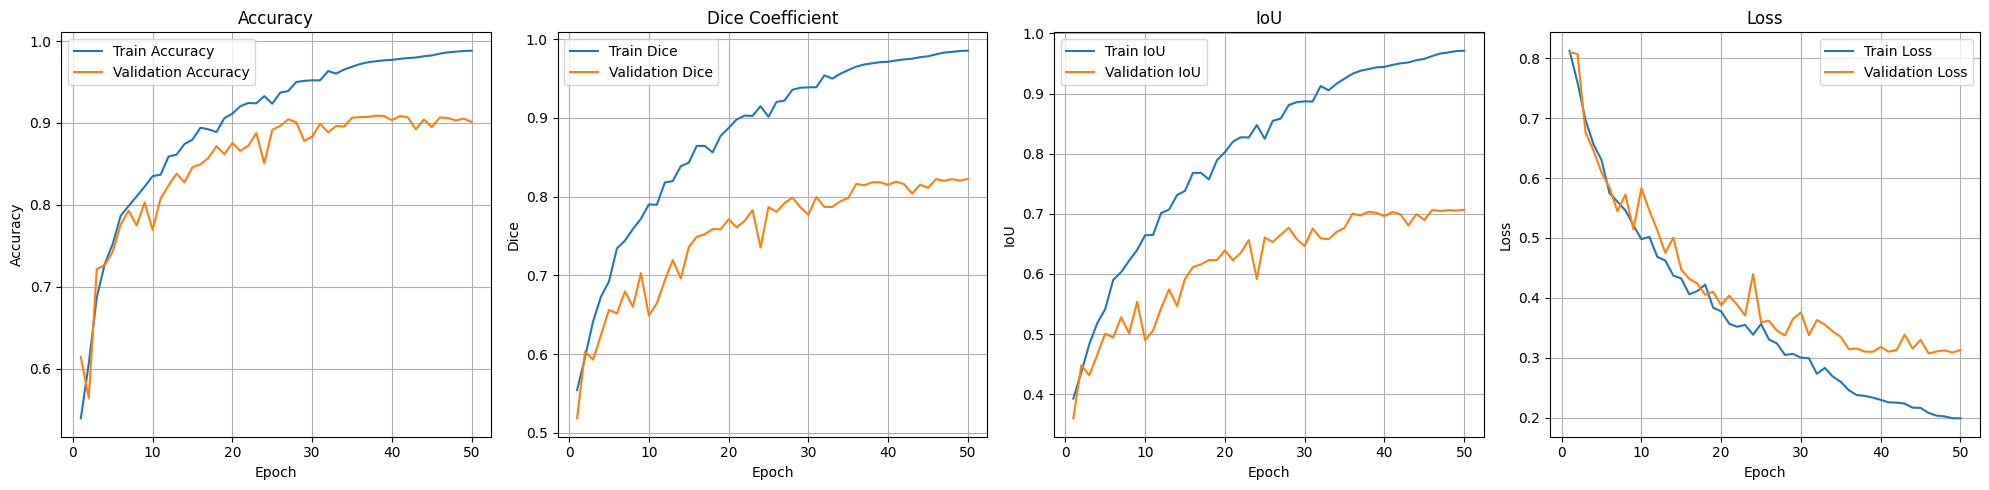

Saved training history and inference model to: /raid/home/dgx1725/unetpp_mod3_learnablekernel_warwick_outputs


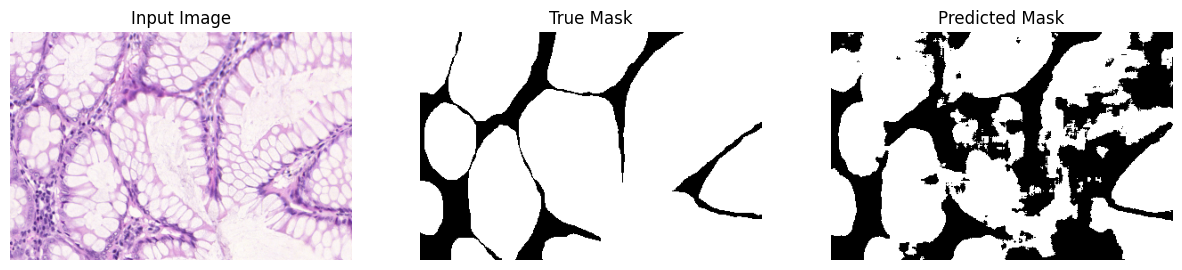

In [5]:
# =========================
# CALLBACK: EVALUATE AVERAGED OUTPUT MODEL
# =========================
class EvaluateAveragedModel(tf.keras.callbacks.Callback):
    def __init__(self, averaged_model, val_ds):
        super().__init__()
        self.averaged_model = averaged_model
        self.val_ds = val_ds

    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}

        results = self.averaged_model.evaluate(
            self.val_ds,
            verbose=0,
            return_dict=True
        )

        logs["val_avg_loss"] = float(results["loss"])
        logs["val_avg_accuracy"] = float(results["accuracy"])
        logs["val_avg_dice_coef"] = float(results["dice_coef"])
        logs["val_avg_iou_coef"] = float(results["iou_coef"])

        print(
            f"\nval_avg_loss={logs['val_avg_loss']:.4f}  "
            f"val_avg_accuracy={logs['val_avg_accuracy']:.4f}  "
            f"val_avg_dice_coef={logs['val_avg_dice_coef']:.4f}  "
            f"val_avg_iou_coef={logs['val_avg_iou_coef']:.4f}"
        )

paper_eval_cb = EvaluateAveragedModel(infer_model, val_ds_single)

# =========================
# CALLBACKS
# =========================
callbacks = [
    paper_eval_cb,
    tf.keras.callbacks.ModelCheckpoint(
        os.path.join(OUTPUT_DIR, "best_unetpp_mod3_learnablekernel_train.keras"),
        monitor="val_avg_dice_coef",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_avg_dice_coef",
        mode="max",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_avg_dice_coef",
        mode="max",
        factor=0.5,
        patience=4,
        verbose=1
    )
]

# =========================
# TRAIN
# =========================
history = train_model.fit(
    train_ds_multi,
    validation_data=val_ds_multi,
    epochs=EPOCHS,
    callbacks=callbacks
)

# =========================
# PLOTS
# =========================
def plot_training_curves(history):
    hist = history.history
    epochs_range = range(1, len(hist["loss"]) + 1)
    plt.figure(figsize=(20, 5))

    plt.subplot(1, 4, 1)
    if "side_4_accuracy" in hist:
        plt.plot(epochs_range, hist["side_4_accuracy"], label="Train Accuracy")
    if "val_avg_accuracy" in hist:
        plt.plot(epochs_range, hist["val_avg_accuracy"], label="Validation Accuracy")
    plt.title("Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 4, 2)
    if "side_4_dice_coef" in hist:
        plt.plot(epochs_range, hist["side_4_dice_coef"], label="Train Dice")
    if "val_avg_dice_coef" in hist:
        plt.plot(epochs_range, hist["val_avg_dice_coef"], label="Validation Dice")
    plt.title("Dice Coefficient")
    plt.xlabel("Epoch")
    plt.ylabel("Dice")
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 4, 3)
    if "side_4_iou_coef" in hist:
        plt.plot(epochs_range, hist["side_4_iou_coef"], label="Train IoU")
    if "val_avg_iou_coef" in hist:
        plt.plot(epochs_range, hist["val_avg_iou_coef"], label="Validation IoU")
    plt.title("IoU")
    plt.xlabel("Epoch")
    plt.ylabel("IoU")
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 4, 4)
    plt.plot(epochs_range, hist["loss"], label="Train Loss")
    if "val_avg_loss" in hist:
        plt.plot(epochs_range, hist["val_avg_loss"], label="Validation Loss")
    plt.title("Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "training_curves.png"), dpi=180, bbox_inches="tight")
    plt.show()

plot_training_curves(history)

# Store training history so runs can be compared later.
pd.DataFrame(history.history).to_csv(
    os.path.join(OUTPUT_DIR, "training_history.csv"), index_label="epoch"
)
# train_model and infer_model share the same underlying trainable layers.
infer_model.save(os.path.join(OUTPUT_DIR, "best_unetpp_mod3_learnablekernel_inference.keras"))
print("Saved training history and inference model to:", OUTPUT_DIR)

# =========================
# PREDICTION + VISUALIZATION
# =========================
def show_prediction(model, pair):
    img_path, mask_path = pair
    img, mask = load_image_mask(img_path.encode(), mask_path.encode())

    pred = model.predict(np.expand_dims(img, axis=0), verbose=0)[0]
    pred_mask = (pred > 0.5).astype(np.uint8)

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(img)
    plt.title("Input Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(mask.squeeze(), cmap="gray")
    plt.title("True Mask")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(pred_mask.squeeze(), cmap="gray")
    plt.title("Predicted Mask")
    plt.axis("off")

    plt.show()

show_prediction(infer_model, val_pairs[0])

[01/16] testB_1.png | IoU=0.7988 | Recall=0.8804 | Precision=0.8961 | Dice_Coefficient=0.8882 | Boundary_F1=0.5035 | Boundary_Recall=0.8778 | Boundary_Precision=0.3530
[02/16] testB_10.png | IoU=0.7391 | Recall=0.8925 | Precision=0.8113 | Dice_Coefficient=0.8500 | Boundary_F1=0.5077 | Boundary_Recall=0.7004 | Boundary_Precision=0.3981
[03/16] testB_11.png | IoU=0.9491 | Recall=0.9780 | Precision=0.9698 | Dice_Coefficient=0.9739 | Boundary_F1=0.8148 | Boundary_Recall=0.8947 | Boundary_Precision=0.7480
[04/16] testB_12.png | IoU=0.7465 | Recall=0.9188 | Precision=0.7993 | Dice_Coefficient=0.8549 | Boundary_F1=0.4070 | Boundary_Recall=0.5280 | Boundary_Precision=0.3311
[05/16] testB_13.png | IoU=0.8559 | Recall=0.9614 | Precision=0.8864 | Dice_Coefficient=0.9224 | Boundary_F1=0.7093 | Boundary_Recall=0.8063 | Boundary_Precision=0.6331
[06/16] testB_14.png | IoU=0.5150 | Recall=0.5630 | Precision=0.8580 | Dice_Coefficient=0.6799 | Boundary_F1=0.2697 | Boundary_Recall=0.3493 | Boundary_Prec

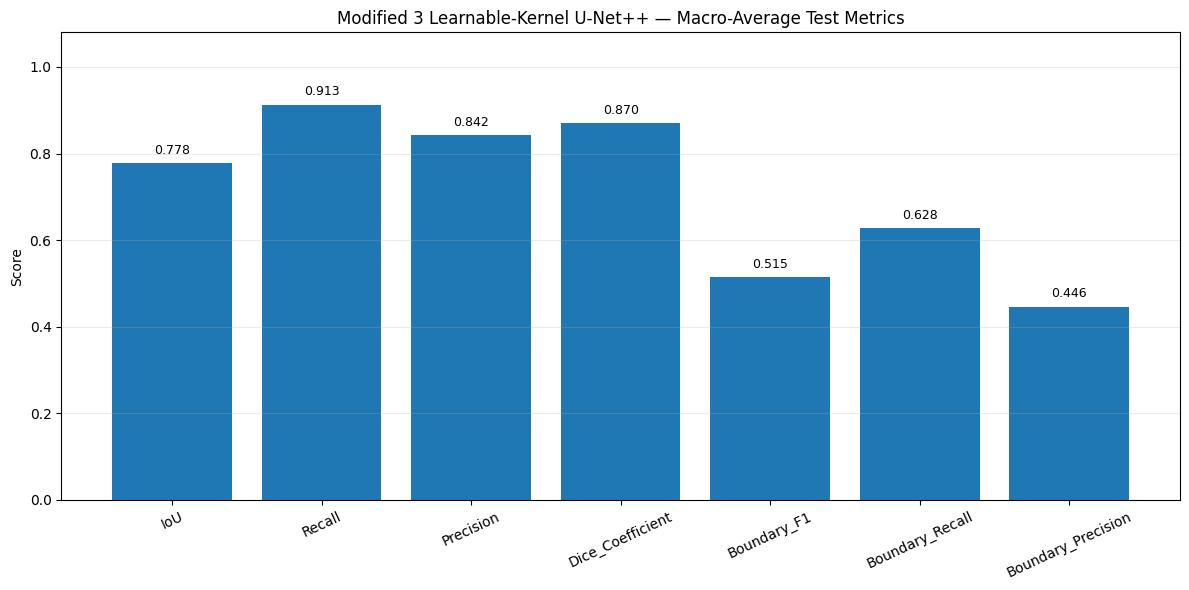

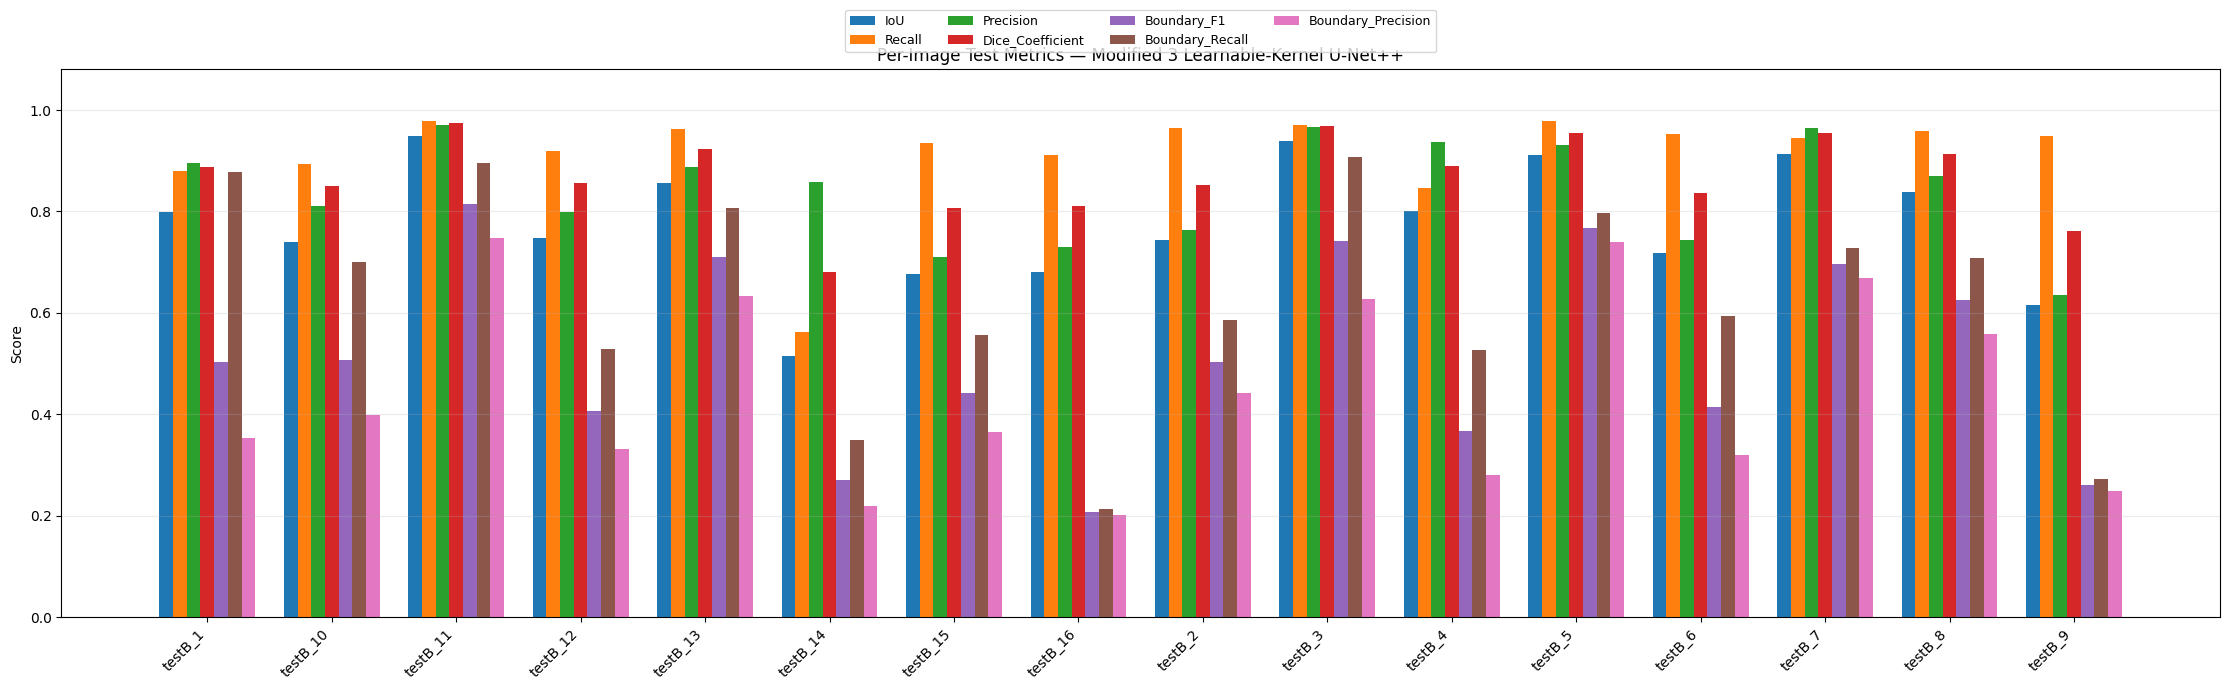


All evaluation artifacts saved under: /raid/home/dgx1725/unetpp_mod3_learnablekernel_warwick_outputs
Boundary scores use only binary mask-derived boundaries and tolerance = 2 pixels.


In [6]:
# =========================
# FINAL PER-IMAGE EVALUATION (7 METRICS)
# =========================
# This section reads test ground truth only from MASK_DIR (binary mask).
# Boundary_Mask_GT is intentionally not read or referenced.

METRIC_NAMES = [
    "IoU", "Recall", "Precision", "Dice_Coefficient",
    "Boundary_F1", "Boundary_Recall", "Boundary_Precision"
]

def safe_ratio(numerator, denominator, empty_value=0.0):
    return float(numerator / denominator) if denominator else float(empty_value)

def binary_boundary(mask_bool):
    """Inner foreground boundary derived from a binary mask by erosion."""
    m = mask_bool.astype(np.uint8)
    erode_kernel = np.ones((3, 3), dtype=np.uint8)
    eroded = cv2.erode(m, erode_kernel, iterations=1)
    return np.logical_and(m > 0, eroded == 0)

def boundary_scores(gt_bool, pred_bool, tolerance_px=BOUNDARY_TOLERANCE_PX):
    gt_boundary = binary_boundary(gt_bool)
    pred_boundary = binary_boundary(pred_bool)

    # A (2*tolerance+1) square kernel allows boundary matches within 2 px
    # in the 8-connected/Chebyshev-distance sense.
    ksize = 2 * int(tolerance_px) + 1
    dilate_kernel = np.ones((ksize, ksize), dtype=np.uint8)
    gt_dilated = cv2.dilate(gt_boundary.astype(np.uint8), dilate_kernel, iterations=1) > 0
    pred_dilated = cv2.dilate(pred_boundary.astype(np.uint8), dilate_kernel, iterations=1) > 0

    gt_count = int(gt_boundary.sum())
    pred_count = int(pred_boundary.sum())
    if pred_count:
        b_precision = float(np.logical_and(pred_boundary, gt_dilated).sum() / pred_count)
    else:
        b_precision = 1.0 if gt_count == 0 else 0.0
    if gt_count:
        b_recall = float(np.logical_and(gt_boundary, pred_dilated).sum() / gt_count)
    else:
        b_recall = 1.0 if pred_count == 0 else 0.0
    b_f1 = (2.0 * b_precision * b_recall / (b_precision + b_recall)) if (b_precision + b_recall) else 0.0
    return b_f1, b_recall, b_precision, gt_boundary, pred_boundary

def calculate_seven_metrics(gt_mask, pred_mask):
    gt = np.asarray(gt_mask).squeeze() > 0.5
    pred = np.asarray(pred_mask).squeeze() > 0.5

    tp = int(np.logical_and(gt, pred).sum())
    fp = int(np.logical_and(~gt, pred).sum())
    fn = int(np.logical_and(gt, ~pred).sum())

    iou = safe_ratio(tp, tp + fp + fn, empty_value=1.0)
    recall = safe_ratio(tp, tp + fn, empty_value=1.0)
    precision = safe_ratio(tp, tp + fp, empty_value=1.0)
    dice = safe_ratio(2 * tp, 2 * tp + fp + fn, empty_value=1.0)

    bf1, brecall, bprecision, gt_boundary, pred_boundary = boundary_scores(gt, pred)
    return {
        "IoU": iou,
        "Recall": recall,
        "Precision": precision,
        "Dice_Coefficient": dice,
        "Boundary_F1": bf1,
        "Boundary_Recall": brecall,
        "Boundary_Precision": bprecision,
    }, gt, pred, gt_boundary, pred_boundary

pred_dir = os.path.join(OUTPUT_DIR, "predicted_masks")
vis_dir = os.path.join(OUTPUT_DIR, "prediction_visualizations")
os.makedirs(pred_dir, exist_ok=True)
os.makedirs(vis_dir, exist_ok=True)

rows = []
for idx, (img_path, mask_path) in enumerate(test_pairs, start=1):
    image, gt_mask = load_image_mask(img_path.encode(), mask_path.encode())
    probability = infer_model.predict(np.expand_dims(image, axis=0), verbose=0)[0]
    pred_mask = (probability >= 0.5).astype(np.uint8)

    metrics, gt_binary, pred_binary, gt_boundary, pred_boundary = calculate_seven_metrics(gt_mask, pred_mask)
    image_stem = os.path.splitext(os.path.basename(img_path))[0]
    row = {"image": os.path.basename(img_path), **metrics}
    rows.append(row)

    pred_path = os.path.join(pred_dir, f"{image_stem}_pred.png")
    cv2.imwrite(pred_path, (pred_binary.astype(np.uint8) * 255))

    # Save an easy-to-inspect 4-panel figure for each test example.
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    axes[0].imshow(image); axes[0].set_title("Input image")
    axes[1].imshow(gt_binary, cmap="gray"); axes[1].set_title("Binary GT mask")
    axes[2].imshow(pred_binary, cmap="gray"); axes[2].set_title("Predicted mask")
    axes[3].imshow(gt_boundary, cmap="gray", alpha=0.75)
    axes[3].imshow(pred_boundary, cmap="autumn", alpha=0.65)
    axes[3].set_title("GT (gray) / Pred boundary")
    for ax in axes:
        ax.axis("off")
    fig.suptitle(f"{image_stem} | Dice={metrics['Dice_Coefficient']:.4f} | Boundary F1={metrics['Boundary_F1']:.4f}")
    fig.tight_layout()
    fig.savefig(os.path.join(vis_dir, f"{image_stem}_evaluation.png"), dpi=150, bbox_inches="tight")
    plt.close(fig)

    print(
        f"[{idx:02d}/{len(test_pairs):02d}] {os.path.basename(img_path)} | "
        + " | ".join(f"{k}={metrics[k]:.4f}" for k in METRIC_NAMES)
    )

if not rows:
    raise RuntimeError("No test rows were evaluated. Verify dataset pairing and split.")

per_image_df = pd.DataFrame(rows)
per_image_csv = os.path.join(OUTPUT_DIR, "per_image_metrics.csv")
per_image_df.to_csv(per_image_csv, index=False)

# Macro average: each test image contributes equally.
summary_df = pd.DataFrame({
    "metric": METRIC_NAMES,
    "macro_average": [float(per_image_df[name].mean()) for name in METRIC_NAMES],
    "std_across_images": [float(per_image_df[name].std(ddof=0)) for name in METRIC_NAMES],
})
summary_csv = os.path.join(OUTPUT_DIR, "summary_metrics.csv")
summary_df.to_csv(summary_csv, index=False)

print("\n=== MACRO-AVERAGE VALIDATION METRICS ===")
for _, metric_row in summary_df.iterrows():
    print(f"{metric_row['metric']:<22} {metric_row['macro_average']:.4f}  (std={metric_row['std_across_images']:.4f})")
print("\nSaved per-image CSV:", per_image_csv)
print("Saved summary CSV:", summary_csv)

# Overall graph, with numeric values printed on bars.
means = summary_df["macro_average"].to_numpy()
fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(METRIC_NAMES, means)
ax.set_title("Modified 3 Learnable-Kernel U-Net++ — Macro-Average Test Metrics")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.08)
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
for bar, value in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.015, f"{value:.3f}", ha="center", va="bottom", fontsize=9)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "test_overall_metrics.png"), dpi=180, bbox_inches="tight")
plt.show()

# Per-image grouped metric graph.
fig, ax = plt.subplots(figsize=(max(14, len(per_image_df) * 1.4), 7))
x = np.arange(len(per_image_df))
width = min(0.11, 0.8 / len(METRIC_NAMES))
for j, metric in enumerate(METRIC_NAMES):
    offsets = x + (j - (len(METRIC_NAMES) - 1) / 2) * width
    ax.bar(offsets, per_image_df[metric].to_numpy(), width=width, label=metric)
ax.set_title("Per-Image Test Metrics — Modified 3 Learnable-Kernel U-Net++")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.08)
ax.set_xticks(x)
ax.set_xticklabels([os.path.splitext(n)[0] for n in per_image_df["image"]], rotation=45, ha="right")
ax.grid(axis="y", alpha=0.25)
ax.legend(ncol=4, bbox_to_anchor=(0.5, 1.02), loc="lower center", fontsize=9)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "test_per_image_metrics.png"), dpi=180, bbox_inches="tight")
plt.show()

print("\nAll evaluation artifacts saved under:", OUTPUT_DIR)
print("Boundary scores use only binary mask-derived boundaries and tolerance =", BOUNDARY_TOLERANCE_PX, "pixels.")
